# 01 · Preprocessing — Young et al. 2018 Kidney Cancer (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony on `sample`), embed, and evaluate **Gate 1** (batch mixing +
manifold continuity) on the *regenerated embedding* across an integration-strength sweep
with a per-neighbourhood metric (iLISI) — never a single scalar.

**The crux of this dataset.** Young et al. profiled several *biologically distinct* kidney
malignancies. The malignant compartment here is a mixture of **adult clear-cell renal-cell
carcinoma (RCC)**, **pediatric embryonal Wilms tumour**, and **papillary RCC** — three
different cancers, not three patients with one disease. Because each sample is (near-)pure for
one tumour type, integrating over `sample` is inseparable from erasing the biological
difference between the cancers. Gate 1 must therefore be judged with that confound made
explicit. Every tunable choice is *derived from this dataset*, not inherited.
Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.stats import chi2_contingency
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                     # 'Young2018_Kidney-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # 'Kidney'
raw  = name[:-2] if name.endswith('-1') else name        # raw input folder lacks the -1 run suffix
pth  = os.path.join(*([os.pardir]*4))                    # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw input:', 'Data_' + raw)

dataset: Young2018_Kidney-1 | category: Kidney | raw input: Data_Young2018_Kidney


### Load the malignant compartment
Young et al. annotate cell type directly; we take their `Malignant` calls. The loader
auto-detects normalization from the matrix filename (`Exp_data_UMIcounts.mtx` → counts →
`normalize_total`) and applies `log1p`.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False); adata.var_names_make_unique()
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant load:', adata.shape[0], 'cells |', adata.obs['sample'].nunique(), 'samples')
print('expression: X in [%.2f, %.2f] (log1p of normalize_total counts)' % (adata.X.min(), adata.X.max()))
print('tumour-type composition (publication cell_subtype):')
print(adata.obs['cell_subtype'].value_counts().to_dict())

full atlas: (125139, 33694)
malignant load: 2055 cells | 25 samples
expression: X in [0.00, 6.69] (log1p of normalize_total counts)
tumour-type composition (publication cell_subtype):
{'Renal_cell_carcinoma': 1467, 'Wilms_tumour': 444, 'Papillary_renal_cell_carcinoma': 144}


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span two orders of magnitude. A round-number cut is not derived;
instead we find the largest **multiplicative** cliff in the sorted counts and cut at its
geometric mean. **C3 check (assumptions stated & met):** the *global* argmax gap lands in the
degenerate 1–3-cell tail (a ratio artefact, not a biological separatrix), so — as the
calibration audit warned for smooth count distributions — we restrict the gap search to the
distribution **body** (both sides ≥ 10 cells) where a cut is meaningful.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
g_glob = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'GLOBAL argmax gap: {int(vals[g_glob])} -> {int(vals[g_glob+1])} (ratio {ratios[g_glob]:.2f})  <- degenerate tail')
body = np.where(vals[1:] >= 10)[0]                       # both sides of the gap >= 10 cells
g = body[int(np.argmax(ratios[body]))]
thresh = int(np.sqrt(vals[g]*vals[g+1]))
print(f'BODY gap (>=10 both sides): {int(vals[g])} -> {int(vals[g+1])} (ratio {ratios[g]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')
print('tumour types retained:', adata.obs['cell_subtype'].value_counts().to_dict())

sorted per-sample counts: [296 278 272 224 137 131 100  99  93  87  87  47  43  38  28  25  17  14
  14   7   6   5   3   3   1]
GLOBAL argmax gap: 3 -> 1 (ratio 3.00)  <- degenerate tail
BODY gap (>=10 both sides): 87 -> 47 (ratio 1.85)
derived threshold (geometric mean across the gap) = 63
kept 11/25 samples -> 1804 cells
tumour types retained: {'Renal_cell_carcinoma': 1373, 'Wilms_tumour': 287, 'Papillary_renal_cell_carcinoma': 144}


### The sample↔tumour-type confound (quantified before any integration)
Before deciding whether Harmony *should* mix these samples, we measure how much `sample`
encodes tumour type. If the two are strongly confounded, "integrating samples" is
"integrating three cancers" — and the resulting continuity would be an artefact of forcing,
not real shared biology.

In [5]:
ct = pd.crosstab(adata.obs['sample'], adata.obs['cell_subtype'])
chi2 = chi2_contingency(ct)[0]; N = ct.values.sum(); r, k = ct.shape
V = np.sqrt(chi2 / (N * (min(r, k) - 1)))
purity = (ct.max(1) / ct.sum(1))
print('per-sample tumour-type composition:'); print(ct.to_string())
print(f'\nCramer V(sample, tumour-type) = {V:.3f}   (1.0 = perfect confound)')
print(f'per-sample majority-type purity: median {purity.median():.3f}, min {purity.min():.3f}')
print(f'samples that are >95% one tumour type: {(purity>0.95).sum()}/{len(purity)}')

per-sample tumour-type composition:
cell_subtype          Papillary_renal_cell_carcinoma  Renal_cell_carcinoma  Wilms_tumour
sample                                                                                  
RCC1_Kid_T_ldc_2_1                                 0                   272             0
RCC1_Kid_T_ldc_2_2                                 0                   296             0
RCC2_Kid_T_ldc_1_1                                 0                   278             0
RCC2_Kid_T_ldc_1_2                                 0                   224             0
RCC2_Kid_T_ldc_2_1                                 0                   131             0
RCC2_Kid_T_ldc_2_2                                 0                   137             0
Wilms1_Kid_R_ldc_1_1                               0                     5            94
Wilms1_Kid_R_ldc_1_2                               0                     5            88
Wilms1_Kid_R_ldc_1_3                               0                     3

### Overdispersion → PCA → Harmony integration-strength sweep
`theta` controls Harmony integration strength. We sweep it and read two per-neighbourhood
quantities on the *regenerated* representation: **iLISI(sample)** (batch mixing; higher =
better) and **iLISI(tumour-type)** (do the three cancers actually intermix?). The well-mixed
*ceilings* (inverse-Simpson of the global frequencies) bound what "fully mixed" means for each
label. n_pcs (20) and UMAP spread (1.3) follow the 10x precedents at this cell count.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, kk=30):
    idx = NearestNeighbors(n_neighbors=kk+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; L = len(np.unique(lab)); out=[]
    for i in range(len(lab)):
        p = np.bincount(lab[idx[i]], minlength=L)/kk; out.append(1.0/np.sum(p**2))
    return np.array(out)

for lab in ['sample','cell_subtype']:
    f = adata.obs[lab].value_counts(normalize=True).values
    print(f'well-mixed iLISI ceiling [{lab}] = {1/np.sum(f**2):.2f}  (levels={len(f)})')

print(f"\n{'theta':>6}{'iLISI_sample':>14}{'iLISI_tumtype':>15}{'kNN_nComp':>11}")
for th in [0, 1, 2, 5, 10, 20]:
    rep = 'X_pca' if th == 0 else 'X_pca_harmony'
    if th > 0:
        sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sc.pp.neighbors(adata, n_pcs=20, use_rep=rep, random_state=SEED)
    nc, _ = connected_components(adata.obsp['connectivities'], directed=False)
    ils = np.median(ilisi(adata.obsm[rep][:,:20], adata.obs['sample']))
    ilt = np.median(ilisi(adata.obsm[rep][:,:20], adata.obs['cell_subtype']))
    print(f'{th:>6}{ils:>14.2f}{ilt:>15.2f}{nc:>11}')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 531 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 531
well-mixed iLISI ceiling [sample] = 8.83  (levels=11)
well-mixed iLISI ceiling [cell_subtype] = 1.64  (levels=3)

 theta  iLISI_sample  iLISI_tumtype  kNN_nComp
     0          1.99           1.00          1
     1          2.83           1.00          1
     2          3.81           1.00          1
     5          4.33           1.23          1
    10          4.55           1.14          1
    20          3.81           1.07          1


The batch metric (iLISI_sample) *improves* with theta, and the kNN graph is a **single
connected component at every theta** — exactly the scalar that would wrongly certify Gate 1.
But **iLISI_tumour-type stays pinned at ~1.0–1.2 against a ceiling of ~1.6 at every integration
strength**: neighbourhoods remain tumour-type-pure no matter how hard we integrate. The three
cancers do not intermix; strong theta only crushes their coordinates together without mixing
their neighbourhoods.

### Regenerate the embedding for the visual Gate-1 read (theta = 2)
We fix a moderate, honest integration (theta = 2 — past the mixing knee but well short of the
collapse that merely overlaps coordinates) and regenerate the UMAP. Gate 1 is read on this
embedding, coloured by both `sample` and tumour type.

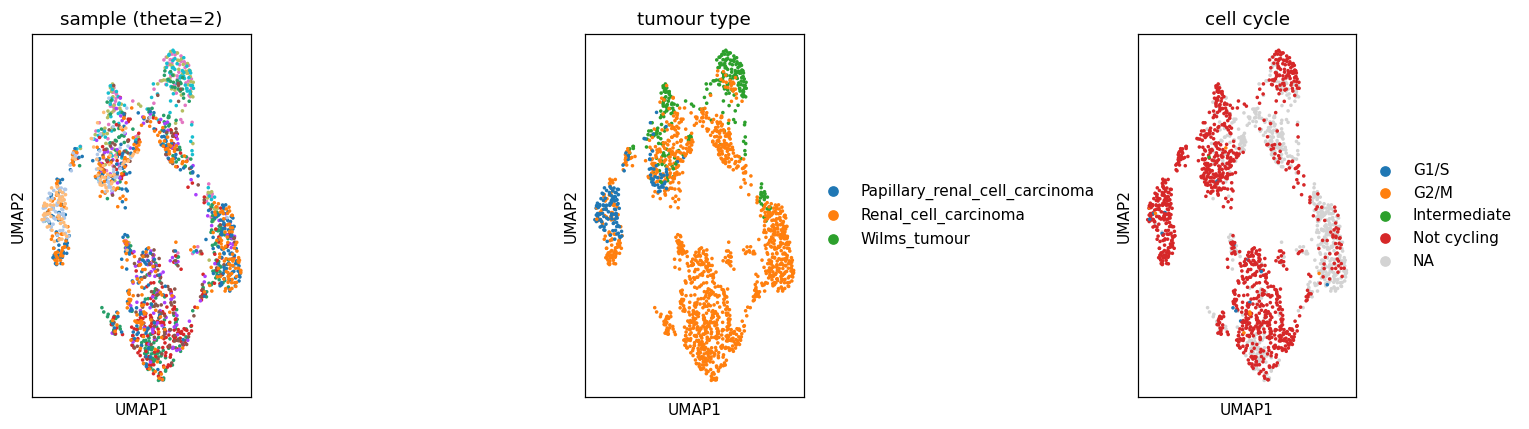

In [7]:
THETA = 2
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
adata.uns['theta'] = THETA
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sc.pl.umap(adata, color='sample', size=22, show=False, ax=axes[0], legend_loc='none', title=f'sample (theta={THETA})')
sc.pl.umap(adata, color='cell_subtype', size=22, show=False, ax=axes[1], title='tumour type')
sc.pl.umap(adata, color='cell_cycle_phase', size=22, show=False, ax=axes[2], title='cell cycle')
fig.tight_layout(); plt.show()

### Sub-region biology — do the developmental signatures form a coherent axis?
Before any Gate-1 GO we settle the sub-regions' biology (the Kürten lobe-identity fork). We
score the three embryonic modules (Gast, pSom, Crest) against the shared **union** control
pool, graph-smooth them, and read their spatial relationships. The reference (non-branching)
pattern requires **Gast and pSom to co-vary** while **both oppose Crest**.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    gg = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=gg, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {gg.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:, j]
print('\nglobal module means (all malignant):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations (geography):')
for x, y in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    print(f'  {x} vs {y}: r = {np.corrcoef(adata.obs[x], adata.obs[y])[0,1]:+.3f}')

Gast: 70/81 genes present
pSom: 83/98 genes present
Crest: 98/104 genes present

global module means (all malignant): {'Gast': -0.0163, 'pSom': 0.0361, 'Crest': -0.0084}
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.374
  Crest_sm vs Gast_sm: r = +0.256
  Crest_sm vs pSom_sm: r = -0.231


The developmental relationships are **inverted** relative to the reference: on this
forced-integration manifold **Gast and pSom are anti-correlated** and **Crest co-varies with
Gast** rather than opposing it. There is no coherent Gast/pSom→Crest developmental axis to
scope a trajectory onto — consistent with the manifold being a composite of three unrelated
cancers rather than one cell-state continuum.

### Gate 1 decision
**Read on the regenerated embedding + the theta sweep + the confound, not on any single
scalar.**

In [9]:
print('=== GATE 1 (batch mixing + manifold continuity) — evidence ===')
print(f'- sample<->tumour-type confound: Cramer V = {V:.2f}; {(purity>0.95).sum()}/{len(purity)} samples >95% one tumour type')
print('- iLISI_tumour-type ~1.0-1.2 vs ceiling ~1.6 at EVERY theta (0->20): the three cancers')
print('    (clear-cell RCC / Wilms / papillary RCC) never intermix at any integration strength')
print('- kNN connected components = 1 at every theta -> the misleading scalar; the embedding and')
print('    the per-neighbourhood metric both show tumour-type-segregated islands, not one gradient')
print('- developmental signatures do NOT form a coherent axis (Gast<->pSom anti-correlated,')
print('    Crest co-varies with Gast) -> no reference cell-state continuum to scope onto')
print()
print('GATE 1 = NO-GO: the malignant compartment is a composite of three biologically distinct')
print('kidney cancers that do not form a single mixed, continuous manifold. Forcing integration')
print('would fabricate a trajectory across unrelated tumour types. No trajectory is fit;')
print('per section 6 the deliverable set is 01 (this) + the unconditional EMT-TF expression step (02).')

=== GATE 1 (batch mixing + manifold continuity) — evidence ===
- sample<->tumour-type confound: Cramer V = 0.93; 7/11 samples >95% one tumour type
- iLISI_tumour-type ~1.0-1.2 vs ceiling ~1.6 at EVERY theta (0->20): the three cancers
    (clear-cell RCC / Wilms / papillary RCC) never intermix at any integration strength
- kNN connected components = 1 at every theta -> the misleading scalar; the embedding and
    the per-neighbourhood metric both show tumour-type-segregated islands, not one gradient
- developmental signatures do NOT form a coherent axis (Gast<->pSom anti-correlated,
    Crest co-varies with Gast) -> no reference cell-state continuum to scope onto

GATE 1 = NO-GO: the malignant compartment is a composite of three biologically distinct
kidney cancers that do not form a single mixed, continuous manifold. Forcing integration
would fabricate a trajectory across unrelated tumour types. No trajectory is fit;
per section 6 the deliverable set is 01 (this) + the unconditional EM

### Save processed data (best-attempt embedding + module scores)

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1804, 19868)


### Sample-integration figure (deliverable `samples.pdf`)
Reference style: a single manifold UMAP coloured by `sample`. Here it is the **Gate-1 NO-GO
evidence** — the samples do not dissolve into one intermixed cloud but remain organised into
tumour-type-segregated territories (each sample is near-pure for one of the three cancers).

saved samples.pdf | cells: 1804


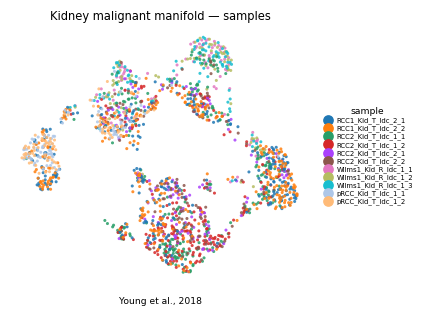

In [11]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, color='sample', size=16, alpha=.85, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.2, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Kidney malignant manifold — samples', size=7.5)
ax.text(.5, -.08, 'Young et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])